Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 48s 110ms/step - accuracy: 0.9167 - loss: 0.2736 - val_accuracy: 0.9818 - val_loss: 0.0619
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 102ms/step - accuracy: 0.9772 - loss: 0.0755 - val_accuracy: 0.9872 - val_loss: 0.0436
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9830 - loss: 0.0549 - val_accuracy: 0.9908 - val_loss: 0.0335
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9870 - loss: 0.0423 - val_accuracy: 0.9902 - val_loss: 0.0385
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 84s 104ms/step - accuracy: 0.9889 - loss: 0.0339 - val_accuracy: 0.9918 - val_loss: 0.0318
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9906 - loss: 0.0285
Test accuracy: 99.06%
Recognized digit: 7
Actual digit: 7


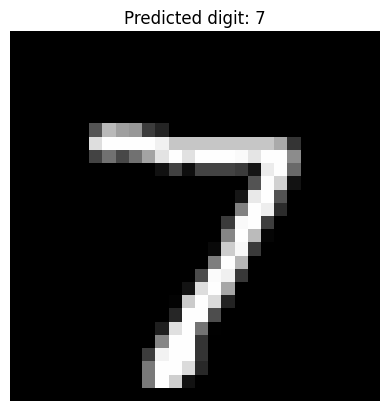

Model saved successfully!


In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        32, kernel_size=3, activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=2),

    tf.keras.layers.Conv2D(
        64, kernel_size=3, activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=2),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation="softmax")
])
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)
loss, accuracy = model.evaluate(x_test, y_test)
print(f"Test accuracy: {accuracy * 100:.2f}%")
index = 0
image = x_test[index]
prediction = model.predict(image[np.newaxis, ...], verbose=0)
digit = np.argmax(prediction[0])
print("Recognized digit:", digit)
print("Actual digit:", y_test[index])
plt.imshow(image.squeeze(), cmap="gray")
plt.title("Predicted digit: {digit}")
plt.axis("off")
plt.show()
model.save("handwritten_model.keras")
print("Model saved successfully!")